In [17]:
import numpy as np
import pandas as pd
# import math
import matplotlib
from matplotlib.patches import Rectangle, Circle
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.ticker import MaxNLocator
from matplotlib.collections import LineCollection


import seaborn as sns
import h5py
import json

from mpl_toolkits.axes_grid1 import make_axes_locatable
from scipy.signal import hilbert, savgol_filter
from scipy.optimize import curve_fit
from scipy.linalg import expm

import os
import sys  
import warnings

from ast import literal_eval

from qutip import  *

sys.path.append('../../scripts') 

from qutip_tools import *

In [18]:
# define measurements following APS rules
cm = 1/2.54  #  everything in cm
plot_aspect_ratio= 0.7

bwidth=9*cm
bheight = plot_aspect_ratio*bwidth
base_font = 9
base_marker = 9

matplotlib.rcParams.update({'font.size': base_font,"legend.fontsize":base_font-4 ,"font.family": "serif", 
                            "font.serif": "CMU Serif, Times New Roman", "axes.labelsize": base_font, "axes.titlesize": base_font,
                            "legend.fontsize": 6, 'text.usetex' : True })

sns.set_palette("colorblind")

fig_route = "../../plots/manuscript_figs/"


In [19]:
ll=100 # QPC size
data_route = "../../data/exact_diag_new/L={}/".format(ll)
J=1


# Functions

## For the dynamics

In [20]:
def get_transmision_proba(gt, K0, Δ):
    # calculate the transmision coefficient for the QPC wavepacket
    # gt = the interaction strength
    # momentum for the integration
    k_arr = np.linspace(-100, 100, 5000)
    m = 1/(2*J**2) # effective mass for the quadratic dispersion

    Psi0k_abs = (Δ ** 2 / np.pi)**(1/2) * np.exp(-Δ**2*(k_arr - K0)** 2 )
    # now with the wave packet weights
    T_k = 1 / (1 + (m*gt / k_arr)** 2)
    T_tot = simpson(T_k * Psi0k_abs, dx=k_arr[1] - k_arr[0])

    return T_tot

def get_qubit_occupations(ρ_list):
    # apply the density opperator to the qubit denisty matrices and return the occupations
    occ_list = []
    # create density operator for the 0th qubit state 
    ketbra = np.outer([1,0], np.conj([1,0]))
    for ρ in ρ_list:
        occ =  np.real(np.trace(ketbra @ ρ))
        occ_list.append(occ)
    return np.asarray(occ_list)

def evolve_q(ρ0 , times, H_qubit):
    # tho0 is the initial denisty matrix of the qubit
    #  times is the array with the time points we evolve to
    ρt = []
    for t in times:
        U = expm(-1j*H_qubit*t)
        ρt.append(U @ ρ0 @ U.conj().T)
    return np.array(ρt)

def extend_qubit_occupations(ρ0, t_init ,d0_density ,times, num_osc=2):
    # evolve the qubit density matrix with the free hamiltonian for a longer time to get the occupations
    # here \rho0 is the last density matrix of the simulated dynamics which we use as initial state
    # first lets extend the range of oscillations of the qubit by applying the independent dynamics as a unitary on the density matrix
    Hqubit = np.zeros((2,2), dtype=complex)
    Hqubit[0,1] = - t_init
    Hqubit[1,0] = - t_init

     # extend the qubit dynamics fro zeno annalysis
    osc_period = np.pi/t_init# period of oscillation

    time_ext = np.arange(times[1], num_osc*osc_period, times[2] - times[1])
    rho_ext = evolve_q(ρ0 , time_ext, Hqubit)

    n0_ext = get_qubit_occupations(rho_ext)
    # shift the time for plotting
    time_ext = time_ext + times[-1] 
    # create the full extended evolution
    n0_full = np.concatenate([d0_density, n0_ext])
    time_full = np.concatenate([times, time_ext])

    return time_full, n0_full

def get_instant_freq(y,time_range):

    # Compute analytic signal via Hilbert transform with padding
    analytic_signal = hilbert(y)
    phase = np.unwrap(np.angle(analytic_signal))
 
    # Compute instantaneous frequency
    dt = np.mean(np.diff(time_range))
    ints_freq = np.gradient(phase, dt)  # rad / (time unit)
    
    # Apply smoothing filter with edge handling
    smooth_freq = savgol_filter(ints_freq, 21, 3, mode='nearest')
        
    return ints_freq, smooth_freq


def estimate_const_freq_fft(y, time_range, remove_mean=True, use_hann=True):
    """Estimate a constant dominant angular frequency with FFT.

    Returns: omega_rad (rad per time unit).
    """

    dt = np.mean(np.diff(time_range))

    # Remove DC to avoid the zero-frequency peak dominating.
    y_proc = y - np.mean(y) if remove_mean else y.copy()

    if use_hann:
        y_proc = y_proc * np.hanning(y_proc.size)

    spec = np.fft.rfft(y_proc)
    freqs = np.fft.rfftfreq(y_proc.size, d=dt)
    power = np.abs(spec) ** 2

    # Ignore DC bin when searching for oscillation frequency.
    start = 1 if power.size > 1 else 0
    peak_idx = np.argmax(power[start:]) + start
    freq_cycles = freqs[peak_idx]
    omega_rad = 2 * np.pi * freq_cycles

    return omega_rad

## For the band structure

In [21]:
def get_second_order(L_qpc, J, krange, eta, Bond):
    # eta is +-t depemndeing on the qubit states
    E2 = []

    for k in krange:
        # remove k so the sums don't blow up
        p_range = np.asarray([x for x in krange if x != k])
        A_N = 1/(L_qpc+1)**2
    
        T1 = A_N*np.sum( (xhi(k, p_range, Bond)**2)/(-2*J*(np.cos(k)-np.cos(p_range))) )
        T2 = A_N*(1/(2*eta))*xhi(k,k,Bond)**2
        T3 = A_N*np.sum( (xhi(k, p_range, Bond)**2)/(-2*J*(np.cos(k)-np.cos(p_range))+2*eta) )
    
        E2.append(T1 + T2 + T3) 
        
    E2 = np.asarray(E2)
    
    return E2

def get_projection_colors(state_list, Proj):
    # get the colors for the band in staet list
    # acording to the matrix element of the projection Proj
    colors_ = []
    # calculate the colors
    for i in range(0,np.shape(state_list)[1]):
        # for plus states
        ev = state_list[:,i]
        ev_proj = np.matmul(Proj,ev)
        colors_.append(np.dot(np.conj(ev), ev_proj))
        
    return np.asarray(colors_)


def schmidt_qubit_qpc(c_eigs):
    # calculates the schmidt decomposition between the QPC and qubit for some stae
    # given how we build our hamiltonian, the 0qubit-eigenstates are in the even indices
    # while the 1qubit ones are in the odd indices
    # c_eigs is the state vector

    # arange in MPS form for SVD
    col_1 = np.asarray(c_eigs[0::2]).reshape(-1,1)
    col_2 =  np.asarray(c_eigs[1::2]).reshape(-1,1)
    psi_mat = np.concatenate((col_1, col_2), axis=1)
    U, S, Vh = np.linalg.svd(psi_mat)

    return U, S, Vh

def get_QPC_occupations(Psi, L_qpc):
    # apply the density opperator to the full composite Psi and return the
    # densities a teach of the QPC sites
    occ_list = []

    for j in range(0,L_qpc):
        basis_j = np.zeros(L_qpc)
        basis_j[j] = 1
        # create density operator for the jth qoc lattice
        ketbra = np.outer(basis_j, np.conj(basis_j))
        # tensor with the qubit identity
        Nj_op = np.kron(ketbra, np.eye(2))
        occ_list.append(np.vdot(Psi, Nj_op @ Psi).real)
    return np.asarray(occ_list)

def create_bands_by_overlaps(free_eigen_vecs, free_energies, eigen_vecs, energies):

    # takes teh decoupled egienvectors, the interacting ines
    # and then sorts them into symmteric and asymbands, 
    # returns the properly sorted energies and eigenvectors of both cases

    # over_matrix is the overlap matrix in case we want to check it later
    sorted_indices, over_matrix = sort_by_overlap_matrix(energies, free_eigen_vecs, eigen_vecs)

    # now sort the freee case into bands according to projection
    mindices, pindices = sort_by_projection(free_energies,free_eigen_vecs, Psym)

    # minus band
    free_energies_m = free_energies[mindices]
    free_states_m = free_eigen_vecs[:,mindices]
    # sort by magnitude
    free_energies_m, free_states_m = mag_sort(free_energies_m, free_states_m)

    # plus band
    free_energies_p = free_energies[pindices]
    free_states_p = free_eigen_vecs[:,pindices]
    # sort by magnitude
    free_energies_p, free_states_p = mag_sort(free_energies_p, free_states_p)

    # now sort the coupled eigenvectors and values according to max overlaps so they match with the free case
    sorted_e = energies[sorted_indices]
    sorted_vecs = eigen_vecs[:,sorted_indices]

    # minus band
    over_energies_m = sorted_e[mindices]
    over_states_m = sorted_vecs[:,mindices]
    # sort by magnitude
    over_energies_m, over_states_m = mag_sort(over_energies_m, over_states_m)

    # plus band
    over_energies_p = sorted_e[pindices]
    over_states_p = sorted_vecs[:,pindices]
    # sort by magnitude
    over_energies_p, over_states_p = mag_sort(over_energies_p, over_states_p)

    return free_energies_m, free_energies_p, free_states_m, free_states_p, over_energies_m, over_energies_p, over_states_m, over_states_p

def calculate_eigen_entropies(over_states_p, over_states_m):
    # calculates the entropy contributios of the sorted eigenstates using schmidt deco

    Svn_p = np.zeros(LL)
    Svn_m = np.zeros(LL)

    for kind in range(0, LL):
        # choose some eigenstate in the symmetric band
        U, S, Vh = schmidt_qubit_qpc(over_states_p[:,kind])
        schmis = S**2
        # calculate the entropy
        Svn_p[kind] = -1*np.sum(schmis*np.log(schmis))
        # choose some eigenstate in the anti-symetric band
        U, S, Vh = schmidt_qubit_qpc(over_states_m[:,kind])
        schmis = S**2
        # calculate the entropy
        Svn_m[kind] = -1*np.sum(schmis*np.log(schmis))

    return Svn_p, Svn_m

In [22]:
def filter_resonant_pairs(k_max_Svn_p, k_max_Svn_m, J, t_):
    # grabs two arrays (each representing momenta from different bands) an
    # picks the 2 pais which best fulfill the resonant condition
    difs = []
    k_pairs = []
    for i in range(0,len(k_max_Svn_p)):
        for j in range(0, len(k_max_Svn_m)):
            difs.append(np.abs(2*J*np.cos(k_max_Svn_p[i]) - 2*J*np.cos(k_max_Svn_m[j])))
            k_pairs.append((k_max_Svn_p[i], k_max_Svn_m[j]))
    
    difs_arr = np.asarray(difs)
    idx_two = np.argsort(np.abs(difs_arr - 2*t_))[:2]
    
    closest_difs = difs_arr[idx_two]
    closest_pairs = [k_pairs[i] for i in idx_two]
    
    return closest_difs, closest_pairs


## REading and writing data

In [23]:
def encode_array(x):
    return json.dumps(np.asarray(x).tolist())

def decode_array(s):
    return np.asarray(json.loads(s))

def encode_complex_matrix_list(rho_list):
    return json.dumps([
        [[[z.real, z.imag] for z in row] for row in np.asarray(rho)]
        for rho in rho_list
    ])

def decode_complex_matrix_list(s):
    raw = json.loads(s)
    return [
        np.array([[complex(re, im) for re, im in row] for row in mat], dtype=complex)
        for mat in raw
    ]

# generate a quick gaussian

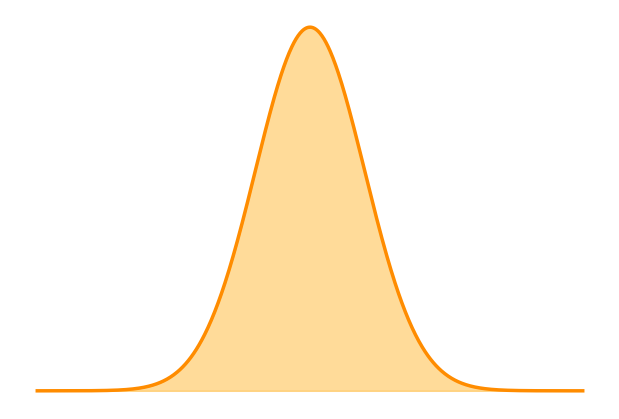

In [24]:
x = np.linspace(-5, 5, 800)
mu = 0.0
sigma = 1.0
y = np.exp(-0.5 * ((x - mu) / sigma) ** 2) / (sigma * np.sqrt(2 * np.pi))

fig, ax = plt.subplots(figsize=(6, 4), facecolor="none")
fig.patch.set_alpha(0)
ax.set_facecolor("none")
ax.fill_between(x, y, color="orange", alpha=0.4)
ax.plot(x, y, color="darkorange", linewidth=2.5)
ax.axis("off")

plt.tight_layout(pad=0)
plt.savefig(fig_route + "gaussian_transparent.pdf", transparent=True, bbox_inches="tight", pad_inches=0)
plt.show()

# Generate analysis Dataframe and save it
the reason I create a new dataframe instead of loading it is becasue its a pain to load 2d arrays this way and its just easier to generate them

In [25]:
#file_list = get_file_names_on(["om0.1"], data_route)
#len(file_list)

In [26]:

"""#read the parameter dictionary to initialize 
param_dict, times, occupations, d0_density, qubit_rho, entropy = load_exact_diag(data_route, file_list[0])  

data_dict =  {key: [] for key in param_dict}
data_dict["times"] = []
data_dict["occupations"] = []
data_dict["d0_density"] = []
data_dict["qubit_rho"] = []
data_dict["entropy"] = []
data_dict["time_at_bond"] = []
data_dict["Max_entropy"] = []
data_dict["cos_theta"] = []
data_dict["sin_phi"] = []
data_dict["bloch_radius"] = []
data_dict["backaction_time"] = []
data_dict["backaction_max"] = []
data_dict["Delta_phi"] = []
data_dict["Delta_phi_max"] = []
data_dict["bloch_radius_last"] = []
data_dict["purity"] = []
data_dict["purity_last"] = []
data_dict["transmission"] = []
data_dict["max_transmission"] = []
data_dict["rabi_final"] = []

def get_bloch_vectors(ρ_list):
    bloch_vecs = []
    for ρ in ρ_list:
        bloch_vecs.append([
            2*np.real(ρ[0,1]),
            -2*np.imag(ρ[0,1]),
            np.real(ρ[0,0] - ρ[1,1]),
        ])
    return np.asarray(bloch_vecs)

problem_cases = []

for i in range(0,len(file_list)):
    file_name = file_list[i]
    param_dict, times, occupations, d0_density, qubit_rho, entropy = load_exact_diag(data_route, file_name) 
    # initialize the meta data
    for key in param_dict.keys():
        data_dict[key].append(param_dict[key])

    #  estimate the time that wavepacket spends at bondf
    bond_density = occupations[param_dict["bond_index"], :] + occupations[param_dict["bond_index"]+1, :]
    tau_bond = get_time_at_bond(times, bond_density)
    
    # get the bloch angles fo the qubit
    costheta_list, sinphi_list = get_bloch_angles_time(qubit_rho)

    # get the backaction
    rho_free_list, theta_free_list, phi_free_list = get_free_orbit(qubit_rho[0], costheta_list[0], param_dict["phi"],
                                                                   times,param_dict["t"])
    
    bloch_interacting = get_bloch_vectors(qubit_rho)
    bloch_free = get_bloch_vectors(rho_free_list)

    # use the full Bloch vectors so we do not lose quadrant/sign information
    backaction = np.linalg.norm(bloch_interacting[1:] - bloch_free[1:], axis=1)
    
    purity_t = get_purity(qubit_rho)
    bloch_radius = np.linalg.norm(bloch_interacting[:], axis=1) # np.sqrt(2*purity_t[1:]-1).real

    # estimate the azimuthal phase gain directly from the Bloch vectors
    #cos_ϕ = (1 + bloch_radius**2 - backaction**2) / (2*bloch_radius)
    # Δϕ = np.arccos(np.clip(cos_ϕ, -1.0, 1.0))
    Δϕ = np.arccos(np.sum(bloch_free * bloch_interacting, axis=1)/bloch_radius )
    
    # first lets extend the range of oscillations of the qubit by applying the independent dynamics as a unitary on the density matrix
    # if param_dict["t"]> 0: 
    #    time_full, n0_full = extend_qubit_occupations(qubit_rho[-1], param_dict["t"], d0_density ,times, num_osc=2)
    #    est_rabi= estimate_const_freq_fft(n0_full[len(qubit_rho):], time_full[len(qubit_rho):], remove_mean=True, use_hann=True)
    #    est_t = est_rabi/2
    #else: 
    #    est_t = 0

    est_t = 0

    # occupation to the right of the bond at
    occu_T = np.sum(occupations[param_dict["bond_index"]+2:, :], axis=0)

    # save raw data 
    data_dict["times"].append(encode_array(times))
    data_dict["occupations"].append(encode_array(occupations))
    data_dict["d0_density"].append(encode_array(d0_density)) 
    data_dict["qubit_rho"].append(encode_complex_matrix_list(qubit_rho))
    # normalize entropy by maximally entangled singled 
    data_dict["entropy"].append(encode_array(entropy/np.log(2)))
    # save processed data
    data_dict["time_at_bond"].append(tau_bond)
    data_dict["Max_entropy"].append(entropy[-1]/np.log(2))
    data_dict["cos_theta"].append(encode_array(np.real(costheta_list)))
    data_dict["sin_phi"].append(encode_array(np.real(sinphi_list)))
    data_dict["backaction_time"].append(encode_array(backaction))
    data_dict["bloch_radius"].append(encode_array(bloch_radius.real))
    data_dict["Delta_phi"].append(encode_array(Δϕ))
    data_dict["backaction_max"].append(backaction[-1])
    data_dict["Delta_phi_max"].append(Δϕ[-1])
    data_dict["bloch_radius_last"].append(bloch_radius.real[-1])
    data_dict["purity_last"].append(purity_t.real[-1])
    data_dict["purity"].append(encode_array(purity_t))
    data_dict["transmission"].append(encode_array(occu_T))
    data_dict["max_transmission"].append(occu_T[-1])
    data_dict["rabi_final"].append(est_t)


full_data_df = pd.DataFrame.from_dict(data_dict)
"""

'#read the parameter dictionary to initialize \nparam_dict, times, occupations, d0_density, qubit_rho, entropy = load_exact_diag(data_route, file_list[0])  \n\ndata_dict =  {key: [] for key in param_dict}\ndata_dict["times"] = []\ndata_dict["occupations"] = []\ndata_dict["d0_density"] = []\ndata_dict["qubit_rho"] = []\ndata_dict["entropy"] = []\ndata_dict["time_at_bond"] = []\ndata_dict["Max_entropy"] = []\ndata_dict["cos_theta"] = []\ndata_dict["sin_phi"] = []\ndata_dict["bloch_radius"] = []\ndata_dict["backaction_time"] = []\ndata_dict["backaction_max"] = []\ndata_dict["Delta_phi"] = []\ndata_dict["Delta_phi_max"] = []\ndata_dict["bloch_radius_last"] = []\ndata_dict["purity"] = []\ndata_dict["purity_last"] = []\ndata_dict["transmission"] = []\ndata_dict["max_transmission"] = []\ndata_dict["rabi_final"] = []\n\ndef get_bloch_vectors(ρ_list):\n    bloch_vecs = []\n    for ρ in ρ_list:\n        bloch_vecs.append([\n            2*np.real(ρ[0,1]),\n            -2*np.imag(ρ[0,1]),\n       

In [27]:
"""# only save the data that we use
#cond_ = (full_data_df["Omega"].isin([0.1, 0.2, 1.0]) )  & (full_data_df["qubit_init"]=="fixed") & (full_data_df["X0"]==30) & (full_data_df["alfabond"]==0.6283185307179586) 
cond_ = (full_data_df["X0"]==30) & (full_data_df["K0"]>0.6) & (full_data_df["t"].isin([1.0e-04,0.4,2.0]))

full_data_df[cond_].sort_values(by="K0").to_csv("../../data/exp_pro/exact_diag_L={}_appendix.csv".format(ll), index=False)"""

#full_data_df.sort_values(by="K0").to_csv("../../data/exp_pro/exact_diag_L={}_fid.csv".format(ll), index=False)

'# only save the data that we use\n#cond_ = (full_data_df["Omega"].isin([0.1, 0.2, 1.0]) )  & (full_data_df["qubit_init"]=="fixed") & (full_data_df["X0"]==30) & (full_data_df["alfabond"]==0.6283185307179586) \ncond_ = (full_data_df["X0"]==30) & (full_data_df["K0"]>0.6) & (full_data_df["t"].isin([1.0e-04,0.4,2.0]))\n\nfull_data_df[cond_].sort_values(by="K0").to_csv("../../data/exp_pro/exact_diag_L={}_appendix.csv".format(ll), index=False)'

# load df


In [28]:
# load dataframe
csv_route = "../../data/exp_pro/exact_diag_L={}.csv".format(ll)
full_data_df = pd.read_csv(
    csv_route,
    converters={
        "times": decode_array,
        "occupations": decode_array,
        "d0_density": decode_array,
        "qubit_rho": decode_complex_matrix_list,
        "entropy": decode_array,
        "cos_theta": decode_array,
        "sin_phi": decode_array,
        "bloch_radius": decode_array,
        "backaction_time": decode_array,
        "Delta_phi": decode_array,
        "purity": decode_array,
        "transmission": decode_array,
    }
)


# Global Params

In [29]:
Om_ = 0.1
X0_ = 30
Δ = 7.0
Δk = 1/(np.sqrt(2)*Δ)
LL = 100
Bindex = full_data_df["bond_index"].sort_values().unique()[0]
# af = full_data_df["alfabond"].sort_values().unique()[1] # af is the qubit  occupation at the time of measurement 
af = 0.6283185307179586
prob0 = np.cos(af/2)**2
print(af)
print("Qubit occupation in state 0 at measurement time:")
print(prob0)

# get some general arrays
K0_unique = full_data_df["K0"].sort_values().unique()
rabi_unique = full_data_df["t"].sort_values().unique()
print(rabi_unique)
cond_ = (full_data_df["Omega"]==Om_)  & (full_data_df["qubit_init"]=="fixed") & (full_data_df["X0"]==X0_) & (full_data_df["alfabond"]==af)

# for the phase diagrams
data_df = full_data_df[cond_].sort_values(by="K0")


0.6283185307179586
Qubit occupation in state 0 at measurement time:
0.9045084971874736
[0.0e+00 1.0e-04 1.0e-03 5.0e-03 1.0e-02 2.0e-02 4.0e-02 6.0e-02 8.0e-02
 1.0e-01 2.0e-01 3.0e-01 4.0e-01 5.0e-01 6.0e-01 7.0e-01 9.0e-01 1.0e+00
 1.5e+00 2.0e+00 5.0e+00]


# Figure 1: Sketch and Trajectory example

choose a single example

In [30]:
full_data_df.Omega.unique()

array([1. , 0.2, 0.1])

In [31]:
t_ = 0.1
Om = 0.2

k0_ = K0_unique[-7] 
print(k0_)
cond_ = (full_data_df["t"]==t_)  & (full_data_df["K0"]==k0_) & (full_data_df["alfabond"]==af) & (full_data_df["Omega"]== Om )

curr_df = full_data_df[cond_].copy()
time_range = np.asarray(curr_df["times"].item())    
Δ = curr_df["Spread"].item() # initial spread of the wavepacket
Bindex = curr_df.bond_index.item()# position of the bond
# spread at time of measurement
Spread_B = (Δ/np.sqrt(2))*np.sqrt(1 + ( (Bindex - X0_)/(Δ*Δ*k0_))**2 )
# density matrix in time 
rhot = curr_df["qubit_rho"].item()


costheta = curr_df["cos_theta"].item()
sinphi = curr_df["sin_phi"].item()
# fix the initial floating point error
sinphi[0] = sinphi[1]
time_range = curr_df["times"].item()
bindex = curr_df["bond_index"].item()
ϕ0 = curr_df["phi"].item()

τbond = (bindex-X0_)/(2*J*np.sin(k0_))
k0_

1.0995574287564276


np.float64(1.0995574287564276)

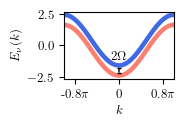

In [32]:
# tigh binding chain dispersion
k_tb = np.linspace(-np.pi, np.pi, ll)

f,ax = plt.subplots(figsize=(0.4*bwidth, 0.35*bheight))
#plt.scatter(k_tb, -2*J*np.cos(k_tb)-4*t_, color="salmon", s=base_marker-5)
#plt.scatter(k_tb, -2*J*np.cos(k_tb)+4*t_, color="royalblue", s=base_marker-5)

plt.plot(k_tb, -2*J*np.cos(k_tb)-4*t_, color="salmon", linewidth=3.3)
plt.plot(k_tb, -2*J*np.cos(k_tb)+4*t_, color="royalblue", linewidth=3.3)

xtau = 0 #np.pi+0.3
ytau = -2
ax.annotate(r'$2\Omega$', xy=(xtau, ytau+0.9), ha="center", fontsize=base_font, fontweight='bold') 

arrow = matplotlib.patches.FancyArrowPatch((xtau, ytau+3.5*t_), (xtau, ytau-3.5*t_),   # move these farther apart to make it longer
                            arrowstyle='-',  mutation_scale=8, lw=1, color='black', zorder=10 )
ax.add_patch(arrow)
# add caps
y_top = ytau + 2.3 * t_
y_bottom = ytau - 2.2 * t_
cap_width = 0.2  # horizontal cap length
ax.hlines([y_top, y_bottom], xtau - cap_width / 2, xtau + cap_width / 2,
           colors="black",linewidth=1,zorder=10)

plt.xlabel(r"$k$", fontsize=base_font)
plt.ylabel(r"$E_\nu(k)$", fontsize=base_font)
plt.xlim(-np.pi, np.pi)
ax.xaxis.set_major_formatter(matplotlib.ticker.FuncFormatter(lambda val,pos: 
                                                             r'{:.1g}$\pi$'.format(val/np.pi) if val !=0 
                                                             else '0'))
ax.tick_params(axis='both', labelsize=base_font)
plt.savefig(fig_route + "tight_binding_dispersion.pdf", bbox_inches="tight", transparent=True)


In [33]:
# extract the bloch angles properly
sintheta = np.sqrt(1-np.real(costheta)**2) 
cosphi = np.sqrt(1-np.real(sinphi)**2) 

theta_time = []
phi_time = []
for i in range(0,len(costheta)):
    theta_time.append(math.atan2(np.real(sintheta[i]), np.real(costheta[i])))
    phi_time.append(math.atan2(np.real(sinphi[i]), np.real(cosphi[i])))


# get THE FREE orbit in bloch sphere
rho_free_list, theta_free_list, phi_free_list = get_free_orbit(rhot[0], costheta[0], ϕ0,
                                                               time_range,t_)
# Now plot the numerical coupled case
dd_theta = np.arccos(costheta)
dd_phi = np.arcsin(sinphi)

x_ = np.sin(dd_theta)*np.cos(dd_phi)
y_ = np.sin(dd_theta)*sinphi
z_ = np.asarray(costheta)

coupled_vectors = [[i,j,k] for i,j,k in zip(x_.real,y_.real,z_.real)]
# make all vectors the same color

# writting out free case solution in spherical coordinates
x_free = np.sin(theta_free_list)*np.cos(phi_free_list)
y_free = np.sin(theta_free_list)*np.sin(phi_free_list)
z_free = np.cos(theta_free_list)

# create the bloch vector for the start of measurement
Mvec = [np.sin(af)*np.cos(np.pi/2), np.sin(af)*np.sin(np.pi/2),np.cos(af)]

np.dot(Mvec,Mvec)

np.float64(1.0)

In [34]:
skip_index = 6
skip_free = 6
# this is for plotting less dense arrows 
vecplot = coupled_vectors[::skip_index]
red_colors = plt.cm.Greens(np.linspace(0.2, 0.9, len(vecplot)))
blue_colors = plt.cm.Purples(np.linspace(0.2, 0.9, len( x_free[::skip_free])))

free_points = [x_free[::skip_free],y_free[::skip_free] , z_free[::skip_free]]
# add the init measurement state
# vecplot.append(Mvec)

red_colors = np.vstack([red_colors])

### Qutip Bloch Sphere

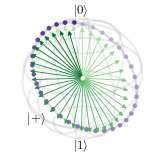

Bloch data:
-----------
Number of points:  1
Number of vectors: 44

Bloch sphere properties:
------------------------
font_color:      black
font_size:       9
frame_alpha:     0.15
frame_color:     gray
frame_width:     0.001
point_default_color:['b', 'r', 'g', '#CC6600']
point_marker:    ['o', 's', 'd', '^']
point_size:      [5, 5, 5]
sphere_alpha:    0.0
sphere_color:    #FFDDDD
figsize:         [1.4173228346456694, 1.4173228346456694]
vector_default_color:['g', '#CC6600', 'b', 'r']
vector_width:    0.6
vector_style:    -|>
vector_mutation: 6
view:            [-60, 30]
xlabel:          ['$|+\\rangle$', ' ']
xlpos:           [1.4, -1.3]
ylabel:          ['', ' ']
ylpos:           [1.2, -1.2]
zlabel:          ['$\\left|0\\right>$', '$\\left|1\\right>$']
zlpos:           [1.25, -1.35]



In [35]:


bs = Bloch()

bs.add_vectors(vecplot)
bs.vector_color = red_colors
bs.vector_width = 0.6
bs.vector_mutation = 6

# now add the free vectors
bs.add_points(free_points)
bs.point_color = list(blue_colors)
bs.point_size= [5]*len(free_points)

# modifying the figure parameters
bs.figsize = [0.4*bwidth, 0.4*bwidth]
bs.font_size = base_font
bs.xlabel = [r"$|+\rangle$", r" "]  
bs.xlpos = [1.4, -1.3]
bs.ylabel = [r"", r" "]  
bs.zlpos = [1.25, -1.35]

bs.sphere_alpha = 0.0
bs.frame_alpha = 0.15
bs.frame_width = 0.001
bs.axis_alpha = 0.1
bs.axis_width = 0.0

bs.show()

print(bs)

# bs.save(fig_route + "bloch_orbits.pdf")

### Custom BLoch

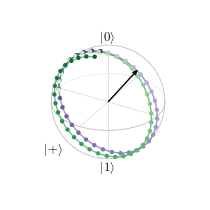

In [36]:
def bloch_frame(ax, elev=20, azim=-60, lw=0.6, color="k", labels=True, fs=9, zorder=0):
    """stripped Bloch sphere: silhouette circle, equator, x/y/z axes"""
    ax.set_proj_type("ortho")
    ax.view_init(elev=elev, azim=azim)
    phi = np.linspace(0, 2*np.pi, 300)

    e, a = np.deg2rad(elev), np.deg2rad(azim)
    v = np.array([np.cos(e)*np.cos(a), np.cos(e)*np.sin(a), np.sin(e)])
    u1 = np.cross([0, 0, 1], v); u1 /= np.linalg.norm(u1)
    u2 = np.cross(v, u1)
    rim = np.outer(u1, np.cos(phi)) + np.outer(u2, np.sin(phi))
    ax.plot(*rim, color=color, lw=lw, zorder=zorder)

    eq = np.array([np.cos(phi), np.sin(phi), 0*phi])
    front = eq.T @ v >= 0
    ax.plot(*np.where(front, eq, np.nan), color=color, lw=lw, zorder=zorder)
    ax.plot(*np.where(~front, eq, np.nan), color=color, lw=lw, ls=(0, (2, 2)),
            alpha=0.6, zorder=zorder)

    for d in np.eye(3):
        ax.plot(*np.stack([-d, d], axis=1), color=color, lw=lw, alpha=0.5, zorder=zorder)
    if labels:
        ax.text(0, 0, 1.2, r"$|0\rangle$", ha="center", va="bottom", fontsize=fs, zorder=zorder)
        ax.text(0, 0, -1.2, r"$|1\rangle$", ha="center", va="top", fontsize=fs, zorder=zorder)
        ax.text(1.9, 0, 0, r"$|+\rangle$", ha="center", va="center", fontsize=fs, zorder=zorder)

    ax.set_xlim(-1, 1); ax.set_ylim(-1, 1); ax.set_zlim(-1, 1)
    ax.set_box_aspect((1, 1, 1))
    ax.set_axis_off()

def bloch_arrows(ax, vecs, colors, lw=0.8, head=0.12, zorder=2):
    """one arrow from the origin per Bloch vector, colored by colors[i]"""
    for v, c in zip(vecs, colors):
        ax.quiver(0, 0, 0, *v, color=c, lw=lw, arrow_length_ratio=head)


def bloch_points(ax, points, colors, s=4, alpha=1.0, plotlines=False):
    """points in qutip format [xs, ys, zs], colored by colors[i]"""
    xs, ys, zs = points
    ax.scatter(xs, ys, zs, c=colors, s=s, depthshade=False, linewidths=0, alpha=alpha)
    if plotlines==True:
        ax.plot(xs, ys, zs, c=colors[-3], linewidth=1, zorder=0, alpha=0.5)



fig = plt.figure(figsize=(0.7*bwidth, 0.7*bwidth))
ax = fig.add_subplot(projection="3d")
ax.computed_zorder = False                       # respect zorder instead of depth sorting

bloch_frame(ax, elev=30, azim=30, fs=base_font, color="silver")    # same view as QuTiP's default
bloch_points(ax, free_points, blue_colors, s=10, plotlines=True)

# bloch_arrows(ax, vecplot, red_colors, lw=0.99)
bloch_points(ax, np.asarray(vecplot).T, red_colors, s=10,plotlines=True)
bloch_arrows(ax, [Mvec], ["k"], lw=1.0,zorder=100)   # Mvec on top
fig.savefig(fig_route + "bloch_orbits.pdf", bbox_inches="tight", transparent=True)


    

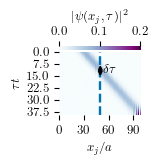

In [37]:

cond_ = (data_df["t"]==t_)  & (data_df["K0"]==k0_)
# rhot = data_S[cond_]["qubit_rho"].item()
n_d1 = data_df[cond_]["d0_density"].item()
traj_matrix = data_df[cond_]["occupations"].item()
time_range = data_df[cond_]["times"].item()


fig, ax = plt.subplots(1,1,figsize=(bwidth*0.3,0.4*bheight))

heat = sns.heatmap(traj_matrix.T, ax=ax, cmap="BuPu",rasterized=True, cbar_kws={"orientation": "horizontal", 
                                                                "location":"top", "pad":0.02, "aspect":20})
ax.set_ylabel(r"$\tau t$",fontsize=base_font)
ax.set_xlabel(r"$x_j/a$", fontsize=base_font)

# time ticks
delta_tau = time_range[1] - time_range[0]
tick_posy = np.arange(0,len(time_range),50)
ytick_label = np.around(tick_posy*(delta_tau),decimals=1)

ax.axvline(curr_df["bond_index"].item(), linewidth=1.7, linestyle="dashed")
ax.set_yticks(tick_posy, ytick_label, fontsize=base_font);

# annotate delta tau inside the plot 
xtau = curr_df["bond_index"].item()
ytau = 63

ax.annotate(r'$\delta \tau$', xy=(xtau+3, ytau+20), fontsize=base_font, fontweight='bold') 
arrow = matplotlib.patches.FancyArrowPatch((xtau, ytau-20), (xtau, ytau+50),   # move these farther apart to make it longer
                            arrowstyle='<->',  mutation_scale=5.5, lw=1.3, color='black', zorder=10 )
ax.add_patch(arrow)

# lattice ticks
xticks = list(np.arange(0, traj_matrix.shape[0])[::30])
ax.set_xticks(xticks, xticks, fontsize=base_font);

heat.collections[0].colorbar.set_label(r"$|\psi(x_j, \tau)|^2$", fontsize=base_font)


plt.savefig(fig_route + "qpc_trajectories.pdf", bbox_inches="tight", transparent=True)

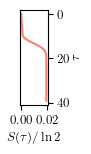

In [38]:
fig, ax = plt.subplots(1,1,figsize=(bwidth*0.1, 0.5*bheight))

data_df[cond_]["entropy"].item()

plt.plot(data_df[cond_]["entropy"].item(), time_range, color="salmon", linewidth=1.5)
ax.set_xlabel(r"$S (\tau)/\ln{2}$", fontsize=base_font)
ax.set_ylabel(r"$\tau$", fontsize=base_font,labelpad=0.3)
ax.yaxis.tick_right()
ax.yaxis.set_label_position("right")
ax.spines["left"].set_visible(True)
ax.spines["right"].set_visible(True)
ax.invert_yaxis()

plt.savefig(fig_route + "entropy_time.pdf", bbox_inches="tight", transparent=True)

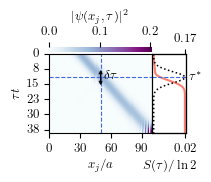

In [39]:
cond_ = (data_df["t"] == t_) & (data_df["K0"] == k0_)

n_d1 = data_df[cond_]["d0_density"].item()
traj_matrix = data_df[cond_]["occupations"].item()
n_bond = np.sum(traj_matrix[Bindex:Bindex+2,:],axis=0)
time_range = data_df[cond_]["times"].item()
# arrival time
dt = time_range[1] - time_range[0]
t0 = time_range[0]
tau_arrive = (Bindex - X0_)/(2*J*np.sin(k0_))
tau_arrive_idx = (np.asarray(tau_arrive) - t0)/dt + 0.5

entropy = np.asarray(data_df[cond_]["entropy"].item())

time_indices = np.arange(len(time_range))

fig, (ax_heat, ax_entropy) = plt.subplots(1,2,figsize=(bwidth * 0.5, 0.5 * bheight),
                                    sharey=True,gridspec_kw={"width_ratios": [3, 1], "wspace": 0.0})

# PLOTTING HEATMAP
# Trajectory heatmap
heat = sns.heatmap(traj_matrix.T, ax=ax_heat,cmap="BuPu",rasterized=True,
                   cbar_kws={ "orientation": "horizontal", "location": "top",
                             "pad": 0.02,"aspect": 20})

ax_heat.set_xlabel(r"$x_j/a$", fontsize=base_font)
ax_heat.set_ylabel(r"$\tau t$", fontsize=base_font)

delta_tau = time_range[1] - time_range[0]
tick_posy = np.arange(0, len(time_range), 50)
#ytick_label = np.around(tick_posy * delta_tau)
ytick_label = np.rint(tick_posy * delta_tau).astype(int)

ax_heat.set_yticks(tick_posy, ytick_label, fontsize=base_font)

#ax_heat.invert_yaxis()

ax_heat.axvline(curr_df["bond_index"].item(),linewidth=0.8,linestyle="dashed", c="royalblue")
ax_heat.axhline(tau_arrive_idx,linewidth=0.8,linestyle="dashed",c="royalblue")

xtau = curr_df["bond_index"].item()
ytau = 63

ax_heat.annotate(r"$\delta \tau$",xy=(xtau + 3, ytau + 20),
                    fontsize=base_font,fontweight="bold")

arrow = matplotlib.patches.FancyArrowPatch( (xtau, ytau - 20),(xtau, ytau + 50),
                arrowstyle="<->", mutation_scale=4.5, lw=1., color="black", zorder=10)

ax_heat.add_patch(arrow)

xticks = list(np.arange(traj_matrix.shape[0])[::30])
ax_heat.set_xticks(xticks, xticks, fontsize=base_font)

heat.collections[0].colorbar.set_label(r"$|\psi(x_j, \tau)|^2$",fontsize=base_font)

# PLOTTING THE ENTROPY

# Align entropy panel with the heatmap body, excluding the colorbar space
heat_pos = ax_heat.get_position()
entropy_pos = ax_entropy.get_position()

ax_entropy.set_position([entropy_pos.x0,heat_pos.y0,
    entropy_pos.width,heat_pos.height])

# Entropy plot aligned with the heatmap time-index axis
ax_entropy.plot(entropy,time_indices,color="salmon",linewidth=1.5)
ax_entropy.axhline(tau_arrive_idx,linewidth=0.8,linestyle="dashed",c="royalblue")

# Keep the top axis visible

ax_entropy.set_xlabel(r"$S(\tau)/\ln{2}$", fontsize=base_font)
ax_entropy.tick_params(axis="y",left=False, labelleft=False)
ax_entropy.set_xticks([max(entropy)], [f"{max(entropy):.1g}"])

ax_entropy.spines["left"].set_visible(True)
ax_entropy.spines["right"].set_visible(True)

# Second x-axis sharing the same y-axis
ax_nbond = ax_entropy.twiny()
ax_nbond.set_position(ax_entropy.get_position())
ax_nbond.plot(n_bond, time_indices,color="black",linewidth=1.1, linestyle="dotted",
    label=r"$g(\tau)$")

ax_nbond.spines["top"].set_visible(True)
ax_nbond.tick_params(axis="x", labelsize=base_font)
# Label for n_bond on top
#ax_nbond.set_xlabel(r"$g(\tau)$",fontsize=base_font,labelpad=6)
ax_nbond.set_xticks([max(n_bond)], [f"{max(n_bond):.2g}"])

# Shared frame enclosing both panels
heat_pos = ax_heat.get_position()
entropy_pos = ax_entropy.get_position()

left = min(heat_pos.x0, entropy_pos.x0)
bottom = min(heat_pos.y0, entropy_pos.y0)
right = max(heat_pos.x1, entropy_pos.x1)
top = max(heat_pos.y1, entropy_pos.y1)

frame = matplotlib.patches.Rectangle(
    (left, bottom),
    right - left,
    top - bottom,
    transform=fig.transFigure,
    fill=False,
    edgecolor="black",
    linewidth=0.8,
    zorder=20,
)

ax_entropy.text(1.08, tau_arrive_idx, r"$\tau^*$",
                transform=ax_entropy.get_yaxis_transform(),   # x: axes, y: data
                ha="left", va="center", fontsize=base_font, clip_on=False)

fig.add_artist(frame)

plt.savefig(fig_route + "qpc_trajectories_entropy.pdf",bbox_inches="tight",transparent=True)

# Figure 2: Backaction and Entanglement on Qubit

In [40]:
# these are the example parameters we chose them so rabi 2 lies on the resonant line
chosen_rabi1 = 0.0001
chosen_rabi2 = 0.4
chosen_rabi3 = 2.0

tlist = [chosen_rabi1,chosen_rabi2, chosen_rabi3]

k0idx = -9

print( "resonant for w =0.4 is momentum =", K0_unique[k0idx])

K0list = [K0_unique[-4], K0_unique[4], K0_unique[1]]
K0_cont = np.linspace(0.1*np.pi/2,np.pi/2,100)

# using the new backaction calcualtion with the proper interaction hamiltonian instead of some translaiton generator
vg_ = 2*J*np.sin(K0_cont)
phase_gain = Om_*(np.tan(K0_cont)**(-1))*(1+1/(2*Δ**2 * np.sin(K0_cont)**2))

# for entropy 
Spread_B =   (Δ/np.sqrt(2))*np.sqrt(1 + ((Bindex - X0_)/(np.tan(K0_cont)*Δ**2 ))**2 )  

# Rexp = ((Om**2)/4) * ( np.tan(K0_cont)**(-2)  + (1+3*np.tan(K0_cont)**(-2))/(2*Spread_B**2 * np.sin(K0_cont)**2) )
#R = np.exp(-(Om_**2)/(4*Spread_B**2)*np.cos(K0_cont)/(np.sin(K0_cont)**3) )
Rexp = 0.5*((Om**2)/np.sin(K0_cont)**2 )*( 1+ (1+np.cos(K0_cont)**2)/(Δ**2 * np.sin(K0_cont)**2) )
R = np.exp(-Rexp/2)
qbloch = np.sqrt((R**2)*np.sin(af)**2 +np.cos(af)**2)

eigen1 = 0.5*(1+qbloch)
eigen2 = 0.5*(1-qbloch)
Sentropt = -eigen1*np.log(eigen1+ 1e-10) - eigen2*np.log(eigen2+ 1e-10)
Sentropt = Sentropt/np.log(2)


resonant for w =0.4 is momentum = 0.942477796076938


## Phase and entropy separated

In [46]:
n_colors = len(tlist)
colors = [plt.cm.Oranges(i/(n_colors+1)) for i in range(1, n_colors+1)]
roman_list = ["I", "II", "III"]

In [47]:
data_df["Delta_phi_max_proper"] = data_df["Delta_phi_max"]/np.sin(data_df["alfabond"])

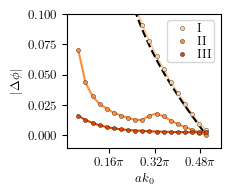

In [48]:
# phase
fig, ax = plt.subplots(1,1,figsize=(2*0.28*bwidth,0.7*bheight))

for i in range(0,len(tlist)):
    ti = tlist[i]
    Rom = roman_list[i]
    # phase
    sns.lineplot(ax=ax, data= data_df[data_df["t"]==ti], x="K0", y="Delta_phi_max_proper", color=colors[i], zorder=0, linewidth=1.5)
    #sns.scatterplot(ax=ax, data= data_df[data_df["t"]==ti], x="K0", y="Delta_phi_max", label=Rom+" " + str(ti), s=base_marker, edgecolor="black",  color=colors[i])
    sns.scatterplot(ax=ax, data= data_df[data_df["t"]==ti], x="K0", y="Delta_phi_max_proper", label=Rom, s=base_marker, edgecolor="black",  color=colors[i])

ax.plot(K0_cont, phase_gain , linestyle="dashed",c="black",zorder=0)

# ax.legend(title=r"$\omega$", bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=base_font+2)
ax.legend(loc='upper right', fontsize=base_font, borderpad=0.2,labelspacing=0.15,handletextpad=0.2)
ax.set_ylim(-0.01,0.1)
ax.set_xlim(0.01*np.pi,0.55*np.pi)


# ax.axvline(Δk, color="blue", linewidth=3, linestyle="dotted")
ax.set_ylabel(r"$|\Delta \phi|$", fontsize=base_font)
ax.set_xlabel(r"$a k_0$", fontsize=base_font)
ax.xaxis.set_major_formatter(matplotlib.ticker.FuncFormatter(lambda val,pos: 
                                                             r'{:.2g}$\pi$'.format(val/np.pi) if val !=0 
                                                             else '0'))

# as a final touch include the label anotations for latex
#ax.annotate(r'(a)', xy=(0.12, 0.085), fontsize=base_font, fontweight='bold')

fig.subplots_adjust(hspace=0.0)  # reduce spacing

plt.savefig(fig_route+"phase_v_k0.pdf", bbox_inches="tight",transparent=True)

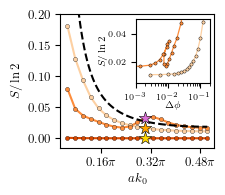

In [ ]:
# now entropy
fig, ax = plt.subplots(1,1,figsize=(2*0.28*bwidth,0.7*bheight))

for i in range(0,len(tlist)):
    ti = tlist[i]
    # entropy
    sns.lineplot(ax=ax, data= data_df[data_df["t"]==ti], x="K0", y="Max_entropy", color=colors[i], zorder=0,linewidth=1.5)
    sns.scatterplot(ax=ax, data= data_df[data_df["t"]==ti], x="K0", y="Max_entropy",color=colors[i], edgecolor="black", s=base_marker)

# ax.plot(K0_cont, Stheo , linestyle="dashed",c="black", zorder=0)

plt.plot(K0_cont, Sentropt, color="black", linestyle="dashed")

# NOW WE PLOT THE EXAMPLES AS STARS TO COMPARE WITH THE PAHSE DIAGRAM
cond_ = (data_df["K0"]==K0_unique[k0idx]) & (data_df["t"]==chosen_rabi1) 
ax.scatter(data_df[cond_]["K0"].item(), data_df[cond_]["Max_entropy"].item(), color="orange", s=base_marker+80,marker="*",  edgecolor="black", linewidth=0.4, zorder=5)

cond_ = (data_df["K0"]==K0_unique[k0idx]) & (data_df["t"]==chosen_rabi2) 
ax.scatter(data_df[cond_]["K0"].item(), data_df[cond_]["Max_entropy"].item(), color="orchid", s=base_marker+80,marker="*",  edgecolor="black", linewidth=0.4, zorder=5)

cond_ = (data_df["K0"]==K0_unique[k0idx]) & (data_df["t"]==chosen_rabi3) 
ax.scatter(data_df[cond_]["K0"].item(), data_df[cond_]["Max_entropy"].item(), color="gold", s=base_marker+80,marker="*",  edgecolor="black", linewidth=0.4, zorder=5)

# ax.legend(title=r"$\omega$", bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=base_font+2)
ax.set_ylim(-0.015,0.2)

# ax.axvline(Δk, color="blue", linewidth=3, linestyle="dotted")
ax.set_ylabel(r'$S/\ln{2}$', fontsize=base_font)
ax.set_xlabel(r"$a k_0$", fontsize=base_font)
ax.xaxis.set_major_formatter(matplotlib.ticker.FuncFormatter(lambda val,pos: 
                                                             r'{:.2g}$\pi$'.format(val/np.pi) if val !=0 
                                                             else '0'))

# as a final touch include the label anotations for latex
#ax.annotate(r'(b)', xy=(0.25, 0.175), fontsize=base_font, fontweight='bold')

# ------------------------------------
# INSET PLOT 
# -----------------------------------

# Inset: 
axins = ax.inset_axes([0.49, 0.48, 0.48, 0.48])
# [left, bottom, width, height] in axes coordinates

k0_target = np.pi / 3
relative_tolerance = 0.20

for i, ti in enumerate(tlist[:2]):
    subset = data_df[data_df["t"] == ti].sort_values("K0")

    # Main inset curves
    axins.plot(subset["Delta_phi_max"],subset["Max_entropy"],
        color=colors[i],linewidth=0.9,zorder=0)
    axins.scatter(subset["Delta_phi_max"],subset["Max_entropy"],color=colors[i],
                  edgecolor="black",linewidth=0.3,s=base_marker * 0.6,zorder=5)

axins.set_xscale("log")
axins.set_ylim(0.005, 0.05)
axins.set_xlim(0.001, 0.2)
axins.tick_params(axis="both", labelsize=base_font - 3)

axins.set_xlabel(r"$\Delta\phi$", fontsize=base_font - 2, labelpad=0.0)
axins.set_ylabel(r"$S/\ln 2$", fontsize=base_font - 2,labelpad=0.0)

# Optional: make the inset boundary visually distinct
for spine in axins.spines.values():
    spine.set_linewidth(0.8)

plt.savefig(fig_route+"entropy_v_k0.pdf", bbox_inches="tight", transparent=True)

## Entanglement phase diagram

In [50]:
# filter out for the parameters we want 
cond_ =(data_df["t"]>0) & (data_df["Omega"]==Om_)  & (data_df["qubit_init"]=="fixed") & (data_df["X0"]==X0_) & (data_df["alfabond"]==af)  & (data_df["K0"]>=0.3*np.pi/2)

data_S = data_df[cond_].sort_values(by="K0")
# FOR NOW
# data_S = data_S.drop_duplicates(subset=["K0", "t"], keep="first")
S_df = data_S.pivot(index='K0', columns='t', values='Max_entropy')
# Create a pivot table for purity l

purity_pivot = data_S.pivot(index='K0', columns='t', values='purity_last')
boundary_points = data_S[data_S["purity_last"]<0.99][["K0","t","purity_last","Delta_phi_max","backaction_max"]]


Do a sweep of the resonant pairs for all rabi frequencies and select the ones that are bein excited by the wavepacket

In [51]:

boundlin = np.arccos(1-rabi_unique[:-1])
lowerlin = 0.5*np.sqrt(2)*vg_/Δ #(Spread_B)
boundlin = 1-np.cos(K0_cont) 
otherline = 1+np.cos(K0_cont) 
otherline

array([1.98768834, 1.98535384, 1.9828184 , 1.98008256, 1.97714687,
       1.97401192, 1.97067835, 1.96714685, 1.96341814, 1.95949297,
       1.95537215, 1.95105652, 1.94654695, 1.94184436, 1.93694972,
       1.93186403, 1.92658831, 1.92112365, 1.91547116, 1.909632  ,
       1.90360734, 1.89739843, 1.89100652, 1.88443293, 1.87767899,
       1.87074608, 1.86363561, 1.85634903, 1.84888783, 1.84125353,
       1.83344769, 1.8254719 , 1.81732778, 1.80901699, 1.80054124,
       1.79190225, 1.78310177, 1.77414161, 1.76502359, 1.75574957,
       1.74632145, 1.73674114, 1.7270106 , 1.7171318 , 1.70710678,
       1.69693757, 1.68662624, 1.6761749 , 1.66558568, 1.65486073,
       1.64400225, 1.63301245, 1.62189357, 1.61064788, 1.59927767,
       1.58778525, 1.57617298, 1.56444322, 1.55259836, 1.54064082,
       1.52857303, 1.51639746, 1.50411659, 1.49173292, 1.47924899,
       1.46666732, 1.4539905 , 1.4412211 , 1.42836173, 1.41541501,
       1.40238359, 1.38927011, 1.37607725, 1.36280771, 1.34946

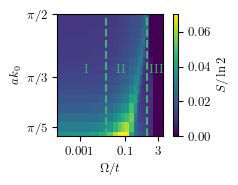

In [ ]:
# Create the phase diagram and reserve a separate axis for the colorbar.
# Create the phase diagram and reserve a separate axis for the colorbar.
fig = plt.figure(
    figsize=(2 * 0.32 * bwidth, 0.7 * bheight),
    constrained_layout=True
)

gs = fig.add_gridspec(
    nrows=1,
    ncols=2,
    width_ratios=[1.0, 0.05],
    wspace=0.08
)


ax = fig.add_subplot(gs[0, 0])
cax = fig.add_subplot(gs[0, 1])

vg_array = S_df.index
t_array = S_df.columns

im = ax.pcolormesh(t_array,vg_array, S_df.values,cmap="viridis",shading="auto",
    vmin=0,vmax=0.07,rasterized=True)

# Add resonant-condition lines.
ax.axvline(0.5 * np.pi / (LL + 1),color="mediumseagreen",
    linewidth=1.5,linestyle="dashed")

ax.axvline(J, color="mediumseagreen",linewidth=1.5,
    linestyle="dashed")

# Axis scale and ticks.
ax.set_xscale("log")
ax.set_xticks([0.001, 0.1, 3],[0.001, 0.1, 3],
    fontsize=base_font)

ax.set_yticks([np.pi / 5, np.pi / 3, np.pi / 2],
              labels=[r"$\pi/5$",r"$\pi/3$",r"$\pi/2$"],
              fontsize=base_font)

ax.set_xlim(0.0001, 5)
ax.set_ylim(0.35 * np.pi / 2, np.pi / 2)

# Regime labels.
ax.annotate(r"I",xy=(0.002, np.pi / 2.9), ha="center",color="mediumseagreen",
            fontsize=base_font,fontweight="bold")

ax.annotate(r"II", xy=(0.07, np.pi / 2.9),ha="center",color="mediumseagreen",
    fontsize=base_font,fontweight="bold")

ax.annotate(r"III",xy=(2.5, np.pi / 2.9),ha="center",color="mediumseagreen",
    fontsize=base_font,fontweight="bold")

# Colorbar in its dedicated axis.
cbar = fig.colorbar(im, cax=cax)
cbar.ax.set_ylabel( r"$S/\ln{2}$",rotation=90,fontsize=base_font)

ax.set_ylabel(r"$a k_0$",fontweight="bold",
    fontsize=base_font)

ax.set_xlabel( r"$\Omega/t$",fontweight="bold",
    fontsize=base_font)

#ax.annotate( r"(c)",xy=(1.5 * 10**(-4), 0.9 * np.pi / 2),
#    fontsize=base_font,fontweight="bold", color="white")

fig.savefig(fig_route + "entropy_vs_K0_and_om.pdf",bbox_inches="tight",
    transparent=True)

# Fig 3: Bandstructure

In [53]:
t_ = 0.4 # 0.001, 0.4,  2.0

# build the projection opeartor to the qubit-symmetric sector of the hilbert space
Id_qpc = np.eye(LL)
plusket = np.asarray([1/np.sqrt(2),1/np.sqrt(2)])
p_ketbra = np.outer(plusket,plusket)
Psym = np.eye(2*LL) - np.kron(Id_qpc, p_ketbra) # tensor product
H_matrix, Hdeco = create_hamiltonians(LL, t_, Bindex, J, Om_)

In [54]:
# Calculate the energies and eigenvectors
energies, eigen_vecs = np.linalg.eig(H_matrix)
# normalize
eigen_vecs = eigen_vecs/ np.linalg.norm(eigen_vecs, axis=0)

# Diagonalize decolupled case
free_energies, free_eigen_vecs = np.linalg.eig(Hdeco)
# normalize
free_eigen_vecs = free_eigen_vecs/ np.linalg.norm(free_eigen_vecs, axis=0)

# calculate the decoupled system analytic eigenenergies (zeroth order correction)
k_single_band = np.arange(1,LL+1)*np.pi/(LL+1)
k_single_band_full = np.concatenate((-k_single_band[::-1], k_single_band))
em0 = -2*J*np.cos(k_single_band) - t_ 
ep0 = -2*J*np.cos(k_single_band) + t_ 
em0_full = np.concatenate((em0[::-1], em0))
ep0_full = np.concatenate((ep0[::-1], ep0))

# sort in to bands by overlaps
free_energies_m, free_energies_p, free_states_m, free_states_p, over_energies_m, over_energies_p, over_states_m, over_states_p = create_bands_by_overlaps(free_eigen_vecs, free_energies, eigen_vecs, energies)


# get the colors for each band 
over_colors_p = get_projection_colors(over_states_p, Psym)
over_colors_m = get_projection_colors(over_states_m, Psym)


/Users/santiago/Desktop/Uni/PhD/qpc_dd/manuscripts_submission/notebooks/analysis/../../scripts/qutip_tools.py:507: RuntimeWarning: divide by zero encountered in matmul
  ev_proj = np.matmul(Proj,ev)
/Users/santiago/Desktop/Uni/PhD/qpc_dd/manuscripts_submission/notebooks/analysis/../../scripts/qutip_tools.py:507: RuntimeWarning: overflow encountered in matmul
  ev_proj = np.matmul(Proj,ev)
/Users/santiago/Desktop/Uni/PhD/qpc_dd/manuscripts_submission/notebooks/analysis/../../scripts/qutip_tools.py:507: RuntimeWarning: invalid value encountered in matmul
  ev_proj = np.matmul(Proj,ev)
/var/folders/2f/glb70vy54y71xvcj1yp0fsnh0000gn/T/ipykernel_46664/2392643537.py:28: RuntimeWarning: divide by zero encountered in matmul
  ev_proj = np.matmul(Proj,ev)
/var/folders/2f/glb70vy54y71xvcj1yp0fsnh0000gn/T/ipykernel_46664/2392643537.py:28: RuntimeWarning: overflow encountered in matmul
  ev_proj = np.matmul(Proj,ev)
/var/folders/2f/glb70vy54y71xvcj1yp0fsnh0000gn/T/ipykernel_46664/2392643537.py:28:

In [55]:
# get entropy contributions
Svn_p, Svn_m = calculate_eigen_entropies(over_states_p, over_states_m)

# mirror the positive-k data so the plot spans the full Brillouin zone
Svn_p_full = np.concatenate((Svn_p[::-1], Svn_p))
Svn_m_full = np.concatenate((Svn_m[::-1], Svn_m))
over_energies_p_full = np.concatenate((over_energies_p[::-1], over_energies_p))
over_energies_m_full = np.concatenate((over_energies_m[::-1], over_energies_m))
over_colors_p_full = np.concatenate((over_colors_p[::-1], over_colors_p))
over_colors_m_full = np.concatenate((over_colors_m[::-1], over_colors_m))

# get the largest entropy contributions'
top_idx_max_Svn_p = np.argpartition(Svn_p, -2)[-2:] 
top_idx_max_Svn_m = np.argpartition(Svn_m, -2)[-2:] 

k_max_Svn_p = k_single_band[top_idx_max_Svn_p]
k_max_Svn_m = k_single_band[top_idx_max_Svn_m]

print("plus band top 2:")
for idx in top_idx_max_Svn_p:
    print("  k/pi =", k_single_band[idx]/np.pi, "  Svn_p =", Svn_p[idx]/np.log(2))
print("minus band top 2:")
for idx in top_idx_max_Svn_m:
    print("  k/pi =", k_single_band[idx]/np.pi, "  Svn_m =", Svn_m[idx]/np.log(2))

print("Momentum Energy differnces: ",)
print( -2*J*np.cos(k_max_Svn_p[0]) + 2*J*np.cos(k_max_Svn_m[0]))
print( -2*J*np.cos(k_max_Svn_p[0]) + 2*J*np.cos(k_max_Svn_m[1]))    
print( -2*J*np.cos(k_max_Svn_p[1]) + 2*J*np.cos(k_max_Svn_m[0]))
print( -2*J*np.cos(k_max_Svn_p[1]) + 2*J*np.cos(k_max_Svn_m[1]))    
print("Band gap= ", 2*t_)
accos_bounds = [np.arccos(-1 + t_) , np.arccos(1 - t_)]
print(accos_bounds)

kupper = k_single_band[k_single_band<=accos_bounds[0]] 
    
E_upper = -2*J*np.cos(kupper) + t_

# momenta where the lower band is degenerate ~
klower = k_single_band[k_single_band>=accos_bounds[1]] 
E_lower = -2*J*np.cos(klower) - t_

# for the well behaved region
DeltaEk = np.diff(-2*J*np.cos(k_single_band)) 

nondegen_indices = np.asarray([ind[0] for ind in np.argwhere(DeltaEk>2*t_)])
if nondegen_indices.size == 0:
    nondegen_indices = [0,0]

# finds the resonant pairs amongs the most entangled states
resonant_difs, resonant_pairs = filter_resonant_pairs(k_max_Svn_p, k_max_Svn_m, J, t_)
print(resonant_difs) 

print(np.asarray(resonant_pairs)/np.pi)


plus band top 2:
  k/pi = 0.029702970297029705   Svn_p = 0.9756784609108277
  k/pi = 0.702970297029703   Svn_p = 0.9864322398244566
minus band top 2:
  k/pi = 0.9702970297029703   Svn_m = 0.9756784609108907
  k/pi = 0.297029702970297   Svn_m = 0.9864322398244139
Momentum Energy differnces: 
-3.9825973918760744
-0.8006809673847051
-0.8006809673847051
2.3812354571066643
Band gap=  0.8
[np.float64(2.214297435588181), np.float64(0.9272952180016123)]
[0.80068097 0.80068097]
[[0.02970297 0.2970297 ]
 [0.7029703  0.97029703]]


In [57]:

def plot_colored_line(axis, x, y, values, linewidth=1.5):
    x = np.asarray(x)
    y = np.asarray(y)
    values = np.real(np.asarray(values))

    points = np.column_stack((x, y)).reshape(-1, 1, 2)
    segments = np.concatenate((points[:-1], points[1:]), axis=1)

    # Color each segment using the mean value at its endpoints
    segment_values = 0.5 * (values[:-1] + values[1:])

    line = LineCollection(segments,cmap=cmap_obj,norm=norm,linewidth=linewidth,
        alpha=1.0,zorder=5,capstyle="butt")
    line.set_array(segment_values)
    axis.add_collection(line)

    return line


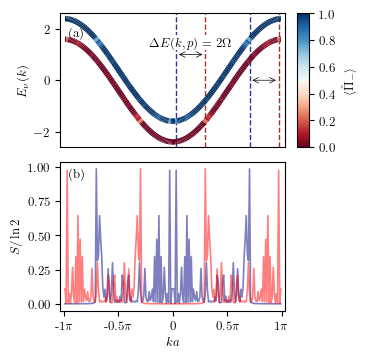

In [58]:
cmap = "RdBu"
cmap_obj = plt.get_cmap(cmap)
c_norm = (0.0, 1.0)
norm = plt.Normalize(*c_norm)

fig = plt.figure(
    figsize=(bwidth, 1.4 * bheight),
    constrained_layout=True
)

gs = fig.add_gridspec(nrows=2,ncols=2,height_ratios=[0.9, 1.0],
    width_ratios=[1.0, 0.055],hspace=0,wspace=0.02)

# Both plot axes use the same left column, so their x-axes align.
ax_top = fig.add_subplot(gs[0, 0])
ax_bottom = fig.add_subplot(gs[1, 0], sharex=ax_top)

# Colorbar axis belongs only to the upper plot.
cax = fig.add_subplot(gs[0, 1])

# Entropy panel
ax_bottom.plot(k_single_band_full,Svn_p_full / np.log(2),color="navy",
    linewidth=1.2, alpha=0.5)

ax_bottom.plot(k_single_band_full,Svn_m_full / np.log(2),color="red",
    linewidth=1.2,alpha=0.5)

# Resonant vertical lines, behind the colored bands
ax_top.axvline(resonant_pairs[0][0], color="Navy",linestyle="--",
    alpha=0.8,linewidth=1.0,zorder=1)

ax_top.axvline( resonant_pairs[0][1],color="Darkred",linestyle="--",
    alpha=0.8,linewidth=1.0,zorder=1)

ax_top.axvline(resonant_pairs[1][0],color="Navy",linestyle="--",
    alpha=0.8,linewidth=1.0,zorder=1)

ax_top.axvline(resonant_pairs[1][1],color="Darkred",linestyle="--",
    alpha=0.8,linewidth=1.0,zorder=1)

# Colored bands
plus_line = plot_colored_line(ax_top,k_single_band_full, over_energies_p_full,
            over_colors_p_full,linewidth=4)
plus_line.set_zorder(20)

minus_line = plot_colored_line(ax_top,k_single_band_full,over_energies_m_full,
    over_colors_m_full,linewidth=4)
minus_line.set_zorder(20)

# First resonant-pair arrow
x1_, x2_ = resonant_pairs[0]
y_ = 1.0

ax_top.annotate(r"$\Delta E(k,p)=2\Omega$", xy=(0.5 * (x1_ + x2_), y_ + 0.35),
    ha="center",fontsize=base_font,fontweight="bold",bbox=dict(facecolor="white",
        edgecolor="none",pad=1))

arrow = matplotlib.patches.FancyArrowPatch((x1_, y_),(x2_, y_),
    arrowstyle="<->",mutation_scale=10, linewidth=0.5,
    color="black",zorder=30)
ax_top.add_patch(arrow)

# Second resonant-pair arrow
x1_, x2_ = resonant_pairs[1]
y_ = 0.0

arrow = matplotlib.patches.FancyArrowPatch((x1_, y_),(x2_, y_),arrowstyle="<->",
    mutation_scale=10,linewidth=0.5,color="black",zorder=30)
ax_top.add_patch(arrow)

# Colorbar only for the upper panel
sm = plt.cm.ScalarMappable(cmap=cmap_obj, norm=norm)
sm.set_array(
    np.concatenate(
        (over_colors_p_full, over_colors_m_full)
    )
)

cbar = fig.colorbar(sm, cax=cax)
cbar.set_label(r"$\langle \hat{\Pi}_- \rangle$",fontsize=base_font)

# Axis labels
ax_top.set_ylabel(r"$E_{\nu}(k)$",fontsize=base_font)
ax_bottom.set_ylabel(r"$S/\ln{2}$",fontsize=base_font)
ax_bottom.set_xlabel(r"$ka$",fontsize=base_font)

# Shared x-axis limits and ticks
ax_top.set_xlim(-np.pi - 0.1, np.pi + 0.1)
ax_top.set_xticks([-np.pi, -np.pi / 2, 0, np.pi / 2, np.pi])

ax_top.xaxis.set_major_formatter(
matplotlib.ticker.FuncFormatter(
        lambda value, position:
        r"{:.0g}$\pi$".format(value / np.pi)
        if value != 0 else "0"
    )
)

# Hide upper x tick labels; the bottom axis displays the shared labels.
ax_top.tick_params(axis="x",which="both",labelbottom=False,  bottom=False,top=False)

# Top-panel y range
ax_top.set_ylim(-2.2 - t_, 2.2 + t_)

# Panel labels
ax_top.annotate(r"(a)",xy=(-0.95 * np.pi, 1.72),fontsize=base_font,
    fontweight="bold")

ax_bottom.annotate(r"(b)",xy=(-0.95 * np.pi, 0.93),
    fontsize=base_font,fontweight="bold")

fig.savefig(fig_route + "band_struct_main.pdf",bbox_inches="tight")

# Appendices

## Different Hit

In [59]:
# load dataframe
csv_route = "../../data/exp_pro/exact_diag_L=100_appendix.csv".format(ll)
appendix_df = pd.read_csv(
    csv_route,
    converters={
        "times": decode_array,
        "occupations": decode_array,
        "d0_density": decode_array,
        "qubit_rho": decode_complex_matrix_list,
        "entropy": decode_array,
        "cos_theta": decode_array,
        "sin_phi": decode_array,
        "bloch_radius": decode_array,
        "backaction_time": decode_array,
        "Delta_phi": decode_array,
        "purity": decode_array,
        "transmission": decode_array,
    }
)

In [60]:

af_unique = np.sort(appendix_df.alfabond.unique())
K0_list = np.sort(appendix_df.K0.unique())

print(af_unique)
print(0,  np.pi/5 , np.pi/2, 3*np.pi/4)
print("occupation at zero at time of hit")
print(np.cos(af_unique/2)**2)


[0.         0.62831853 1.57079633 2.35619449]
0 0.6283185307179586 1.5707963267948966 2.356194490192345
occupation at zero at time of hit
[1.         0.9045085  0.5        0.14644661]


In [61]:
Spread_B =   (Δ/np.sqrt(2))*np.sqrt(1 + ((Bindex - X0_)/(np.tan(K0_list)*Δ**2 ))**2 )  

In [62]:
k_fine  = np.linspace(K0_list.min(), K0_list.max(), 300)
tau_d   = 1.0 / (2*J*np.sin(k_fine))            # dwell time a/v_g  (a = hbar = 1)
g_eff   = Om_ * np.abs(np.cos(af_unique/2))     # one value per theta_M ; Om_ = coupling g in the code
packet  = 1 + (1 + 3/np.tan(k_fine)**2) / (2*Δ**2)   # Gaussian-packet correction (set to 1 for plane wave)

T_geff = [1 - (2*ge*tau_d)**2 * packet for ge in g_eff]  

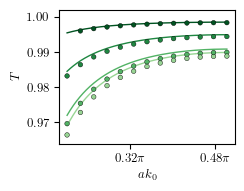

In [63]:
green_palette = sns.color_palette(
    [plt.cm.Greens(value) for value in np.linspace(0.4, 0.95, len(af_unique))])

fig, ax = plt.subplots(1,1,figsize=(2*0.32*bwidth,0.7*bheight))

cond_app = (appendix_df["t"]==1.0e-04)

k = np.linspace(K0_list.min(), K0_list.max(), 300)
w = np.cos(af_unique/2)**2                        # weight of the coupled qubit state (code convention)
R1 = (Om_/J)**2 / np.sin(k)**2 * (1 + (1 + 3/np.tan(k)**2)/(2*Δ**2))   # reflection, qubit fully coupled
for i, wi in enumerate(w):
    ax.plot(k, T_geff[i], c=green_palette[i], lw=1, zorder=0)

sns.scatterplot(data=appendix_df[appendix_df["t"]==1.0e-04], x="K0", y="max_transmission", hue="alfabond", palette=green_palette, 
                edgecolor="black", s=base_marker+2, linewidth=0.3, legend=False)


ax.set_ylim(0.964,1.002)
ax.set_ylabel(r"$T$", fontsize=base_font)
ax.set_xlabel(r"$a k_0$", fontsize=base_font)

ax.xaxis.set_major_formatter(matplotlib.ticker.FuncFormatter(lambda val,pos: 
                                                             r'{:.2g}$\pi$'.format(val/np.pi) if val !=0 
                                                             else '0'))
#x.annotate(r'(a)', xy=(0.195*np.pi, 0.998), fontsize=base_font, fontweight='bold', color="black")

plt.savefig(fig_route+"qubit_occupation.pdf", bbox_inches="tight", transparent=True)

## Rabi Freq

In [64]:
data_df.columns
print(len(data_df))
chosen_rabi_list = [0.001, chosen_rabi2, chosen_rabi3]
rabi_df = data_df[ (data_df["t"].isin(chosen_rabi_list)) & (data_df["K0"].isin(K0_unique[::2])) ].sort_values(by="K0")

399


In [65]:
for index, row in rabi_df.iterrows():
    qubit_rho = np.asarray(row["qubit_rho"])
    d0_density = np.asarray(row["d0_density"])
    times = np.asarray(row["times"])
    t_input = float(row["t"])
    print(index)
    if t_input <= 0:
        est_t = 0.0

    else:
        time_full, n0_full = extend_qubit_occupations(qubit_rho[-1], row["t"], d0_density ,times, num_osc=2)
        est_rabi= estimate_const_freq_fft(n0_full[len(qubit_rho):], time_full[len(qubit_rho):], remove_mean=True, use_hann=True)
        est_t = est_rabi/2

    rabi_df.loc[index, "rabi_final"] = est_t
    rabi_df.loc[index, "rabi_rel_change"] = (est_t - t_input) / t_input if t_input != 0 else 0


39
17
23
153
133
130


/var/folders/2f/glb70vy54y71xvcj1yp0fsnh0000gn/T/ipykernel_46664/2826819542.py:15: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '0.00100002288484307' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  rabi_df.loc[index, "rabi_final"] = est_t


313
281
298
436
403
382
556
550
536
673
645
632
791
818
780
935
943
889
1053
1046
1015
1168
1171
1155


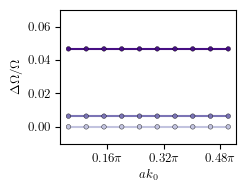

In [66]:
blue_palette = sns.color_palette(
    [plt.cm.Purples(value) for value in np.linspace(0.35, 0.95, len(chosen_rabi_list))])

fig, ax = plt.subplots(1,1,figsize=(2*0.32*bwidth,0.7*bheight))

sns.lineplot(data=rabi_df, x="K0", y="rabi_rel_change", hue="t", palette=blue_palette, linewidth=1.5, ax=ax, legend=False, zorder=0)
sns.scatterplot(data=rabi_df, x="K0", y="rabi_rel_change", hue="t", palette=blue_palette, edgecolor="black", s=base_marker+2, ax=ax, legend=False)

ax.set_ylim(-0.01, 0.07)
ax.set_xlabel(r"$a k_0$", fontsize=base_font)
ax.set_ylabel(r"$\Delta\Omega/\Omega$", fontsize=base_font)
ax.xaxis.set_major_formatter(matplotlib.ticker.FuncFormatter(lambda val,pos: 
                                                             r'{:.2g}$\pi$'.format(val/np.pi) if val !=0 
                                                             else '0'))

#ax.annotate(r'(b)', xy=(0.04*np.pi, 0.175), fontsize=base_font, fontweight='bold', color="black")

plt.savefig(fig_route+"change_in_rabi.pdf", bbox_inches="tight", transparent=True)

## Finite size effects 

In [67]:
NN = 200

# load dataframe
csv_route = "../../data/exp_pro/exact_diag_L={}.csv".format(NN)
big_data_df = pd.read_csv(
    csv_route,
    converters={
        "times": decode_array,
        "occupations": decode_array,
        "d0_density": decode_array,
        "qubit_rho": decode_complex_matrix_list,
        "entropy": decode_array,
        "cos_theta": decode_array,
        "sin_phi": decode_array,
        "bloch_radius": decode_array,
        "backaction_time": decode_array,
        "Delta_phi": decode_array,
        "purity": decode_array,
        "transmission": decode_array,
    }
)


In [68]:
# filter out for the parameters we want 
cond_ =(big_data_df["t"]>0) & (big_data_df["Omega"]==Om_)  & (big_data_df["qubit_init"]=="fixed") & (big_data_df["X0"]==80) & (big_data_df["alfabond"]==af)  & (big_data_df["K0"]>=0.3*np.pi/2)

data_S = big_data_df[cond_].sort_values(by="K0").drop_duplicates(subset=["K0", "t"], keep="first")

# FOR NOW
S_df = data_S.pivot(index='K0', columns='t', values='Max_entropy')


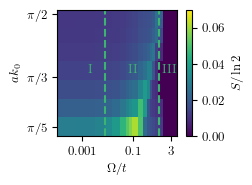

In [69]:
#fig, ax = plt.subplots(1,1,figsize=(2*0.33*bwidth,0.8*bheight))

fig = plt.figure(
    figsize=(2 * 0.34 * bwidth, 0.7 * bheight),
    constrained_layout=True
)

gs = fig.add_gridspec(
    nrows=1,
    ncols=2,
    width_ratios=[1.0, 0.05],
    wspace=0.08
)

ax = fig.add_subplot(gs[0, 0])
cax = fig.add_subplot(gs[0, 1])

vg_array = S_df.index
t_array = S_df.columns

im = ax.pcolormesh(t_array, vg_array, S_df.values, cmap="viridis",shading='auto', vmin=0, vmax=0.07,rasterized=True)

# get axis scale and ticks
ax.set_xscale('log')
ax.set_xticks( [0.001, 0.1,3], [0.001, 0.1,3] ,fontsize=base_font)
ax.set_yticks( [np.pi/5,np.pi/3, np.pi/2], labels=[r"$\pi/5$",r"$\pi/3$",r"$\pi/2$"], fontsize=base_font)
ax.set_xlim(0.0001, 5)

y_tick = np.pi/2

# Mark the regime labels
ax.annotate(r"I", xy=(0.002, np.pi / 2.9),ha='center', c="mediumseagreen", fontweight='bold',fontsize=base_font)

ax.annotate(r"II", xy=(0.1, np.pi / 2.9), ha='center', c="mediumseagreen",fontweight='bold')

ax.annotate(r"III", xy=(2.5, np.pi / 2.9), ha='center', c="mediumseagreen", fontweight='bold')

ax.axvline(0.5*np.pi/(NN+1), color='mediumseagreen',  linestyle="dashed",zorder=1)  
ax.axvline(J, color='mediumseagreen', linestyle="dashed", zorder=1)  

# set up color bar
# Colorbar in its dedicated axis.
cbar = fig.colorbar(im, cax=cax)
cbar.ax.set_ylabel( r"$S/\ln{2}$",rotation=90,fontsize=base_font)

ax.set_ylabel(r"$a k_0$",fontweight='bold', fontsize=base_font)
ax.set_xlabel(r"$\Omega/t$",fontweight='bold', fontsize=base_font)
# add latex labels
#ax.annotate(r'(c)', xy=(1.5*10**(-4), 0.957*np.pi/2), fontsize=base_font, fontweight='bold', color="white")

#plt.tight_layout()

plt.savefig(fig_route+"finite_size.pdf", bbox_inches="tight", transparent=True)


## Fano Peak

In [70]:
print(0.5 * np.pi / (ll + 1))

rabi_list =  rabi_unique[np.where((rabi_unique>0.5 * np.pi / (ll + 1) ) & (rabi_unique < 0.5))[0]][0:]
green_palette = sns.color_palette([plt.cm.Greens(value) for value in np.linspace(0.4, 0.95, len(rabi_list))])


0.015552438879157391


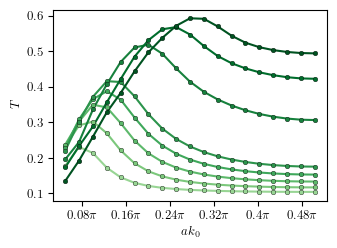

In [72]:
fig, ax = plt.subplots(1,1,figsize=(bwidth, bheight))

for i in range(0,len(rabi_list)):
    ti = rabi_list[i]

    cond =  (full_data_df["alfabond"]==af) & (full_data_df["Omega"]== 1.0 ) & (full_data_df["qubit_init"]=="fixed") & (full_data_df["X0"]==X0_) & (full_data_df["alfabond"]==af) & (full_data_df["t"]==ti) 

    # entropy
    sns.lineplot(data=full_data_df[cond], x="K0", y="max_transmission", color=green_palette[i], linewidth=1.5, ax=ax, zorder=0)
    sns.scatterplot(data=full_data_df[cond], x="K0", y="max_transmission", color=green_palette[i], s=base_marker+2, edgecolor="black", ax=ax)

ax.set_ylabel(r"$T$", fontsize=base_font)
ax.set_xlabel(r"$a k_0$", fontsize=base_font)

ax.xaxis.set_major_formatter(matplotlib.ticker.FuncFormatter(lambda val,pos: 
                                                             r'{:.2g}$\pi$'.format(val/np.pi) if val !=0 
                                                             else '0'))

plt.savefig(fig_route+"fano_transmission.pdf", bbox_inches="tight", transparent=True)


## Band Structure and entropy

This just repeats the code for figure 3 but with different figs

In [73]:
t_ = 2.0 # 2.0 #0.0001  

# build the projection opeartor to the qubit-symmetric sector of the hilbert space
Id_qpc = np.eye(LL)
plusket = np.asarray([1/np.sqrt(2),1/np.sqrt(2)])
p_ketbra = np.outer(plusket,plusket)
Psym = np.eye(2*LL) - np.kron(Id_qpc, p_ketbra) # tensor product
H_matrix, Hdeco = create_hamiltonians(LL, t_, Bindex, J, Om_)

In [74]:
# Calculate the energies and eigenvectors
energies, eigen_vecs = np.linalg.eig(H_matrix)
# normalize
eigen_vecs = eigen_vecs/ np.linalg.norm(eigen_vecs, axis=0)

# Diagonalize decolupled case
free_energies, free_eigen_vecs = np.linalg.eig(Hdeco)
# normalize
free_eigen_vecs = free_eigen_vecs/ np.linalg.norm(free_eigen_vecs, axis=0)

# calculate the decoupled system analytic eigenenergies (zeroth order correction)
k_single_band = np.arange(1,LL+1)*np.pi/(LL+1)
k_single_band_full = np.concatenate((-k_single_band[::-1], k_single_band))
em0 = -2*J*np.cos(k_single_band) - t_ 
ep0 = -2*J*np.cos(k_single_band) + t_ 
em0_full = np.concatenate((em0[::-1], em0))
ep0_full = np.concatenate((ep0[::-1], ep0))

# sort in to bands by overlaps
free_energies_m, free_energies_p, free_states_m, free_states_p, over_energies_m, over_energies_p, over_states_m, over_states_p = create_bands_by_overlaps(free_eigen_vecs, free_energies, eigen_vecs, energies)


# get the colors for each band 
over_colors_p = get_projection_colors(over_states_p, Psym)
over_colors_m = get_projection_colors(over_states_m, Psym)

/Users/santiago/Desktop/Uni/PhD/qpc_dd/manuscripts_submission/notebooks/analysis/../../scripts/qutip_tools.py:507: RuntimeWarning: divide by zero encountered in matmul
  ev_proj = np.matmul(Proj,ev)
/Users/santiago/Desktop/Uni/PhD/qpc_dd/manuscripts_submission/notebooks/analysis/../../scripts/qutip_tools.py:507: RuntimeWarning: overflow encountered in matmul
  ev_proj = np.matmul(Proj,ev)
/Users/santiago/Desktop/Uni/PhD/qpc_dd/manuscripts_submission/notebooks/analysis/../../scripts/qutip_tools.py:507: RuntimeWarning: invalid value encountered in matmul
  ev_proj = np.matmul(Proj,ev)
/var/folders/2f/glb70vy54y71xvcj1yp0fsnh0000gn/T/ipykernel_46664/2392643537.py:28: RuntimeWarning: divide by zero encountered in matmul
  ev_proj = np.matmul(Proj,ev)
/var/folders/2f/glb70vy54y71xvcj1yp0fsnh0000gn/T/ipykernel_46664/2392643537.py:28: RuntimeWarning: overflow encountered in matmul
  ev_proj = np.matmul(Proj,ev)
/var/folders/2f/glb70vy54y71xvcj1yp0fsnh0000gn/T/ipykernel_46664/2392643537.py:28:

In [75]:
# get entropy contributions
Svn_p, Svn_m = calculate_eigen_entropies(over_states_p, over_states_m)

# mirror the positive-k data so the plot spans the full Brillouin zone
Svn_p_full = np.concatenate((Svn_p[::-1], Svn_p))
Svn_m_full = np.concatenate((Svn_m[::-1], Svn_m))
over_energies_p_full = np.concatenate((over_energies_p[::-1], over_energies_p))
over_energies_m_full = np.concatenate((over_energies_m[::-1], over_energies_m))
over_colors_p_full = np.concatenate((over_colors_p[::-1], over_colors_p))
over_colors_m_full = np.concatenate((over_colors_m[::-1], over_colors_m))

# get the largest entropy contributions'
top_idx_max_Svn_p = np.argpartition(Svn_p, -2)[-2:] 
top_idx_max_Svn_m = np.argpartition(Svn_m, -2)[-2:] 

k_max_Svn_p = k_single_band[top_idx_max_Svn_p]
k_max_Svn_m = k_single_band[top_idx_max_Svn_m]

print("plus band top 2:")
for idx in top_idx_max_Svn_p:
    print("  k/pi =", k_single_band[idx]/np.pi, "  Svn_p =", Svn_p[idx]/np.log(2))
print("minus band top 2:")
for idx in top_idx_max_Svn_m:
    print("  k/pi =", k_single_band[idx]/np.pi, "  Svn_m =", Svn_m[idx]/np.log(2))

print("Momentum Energy differnces: ",)
print( -2*J*np.cos(k_max_Svn_p[0]) + 2*J*np.cos(k_max_Svn_m[0]))
print( -2*J*np.cos(k_max_Svn_p[0]) + 2*J*np.cos(k_max_Svn_m[1]))    
print( -2*J*np.cos(k_max_Svn_p[1]) + 2*J*np.cos(k_max_Svn_m[0]))
print( -2*J*np.cos(k_max_Svn_p[1]) + 2*J*np.cos(k_max_Svn_m[1]))    
print("Band gap= ", 2*t_)
accos_bounds = [np.arccos(-1 + t_) , np.arccos(1 - t_)]
print(accos_bounds)

kupper = k_single_band[k_single_band<=accos_bounds[0]] 
    
E_upper = -2*J*np.cos(kupper) + t_

# momenta where the lower band is degenerate ~
klower = k_single_band[k_single_band>=accos_bounds[1]] 
E_lower = -2*J*np.cos(klower) - t_

# for the well behaved region
DeltaEk = np.diff(-2*J*np.cos(k_single_band)) 

nondegen_indices = np.asarray([ind[0] for ind in np.argwhere(DeltaEk>2*t_)])
if nondegen_indices.size == 0:
    nondegen_indices = [0,0]

# finds the resonant pairs amongs the most entangled states
resonant_difs, resonant_pairs = filter_resonant_pairs(k_max_Svn_p, k_max_Svn_m, J, t_)
print(resonant_difs) 

print(np.asarray(resonant_pairs)/np.pi)

plus band top 2:
  k/pi = 0.029702970297029705   Svn_p = 0.001426218842325089
  k/pi = 0.009900990099009901   Svn_p = 0.001472249537550791
minus band top 2:
  k/pi = 0.9702970297029703   Svn_m = 0.0014262188423267948
  k/pi = 0.9900990099009902   Svn_m = 0.0014722495375545598
Momentum Energy differnces: 
-3.9825973918760744
-3.990331260522013
-3.990331260522013
-3.9980651291679523
Band gap=  4.0
[np.float64(0.0), np.float64(3.141592653589793)]
[3.99806513 3.99033126]
[[0.00990099 0.99009901]
 [0.02970297 0.99009901]]


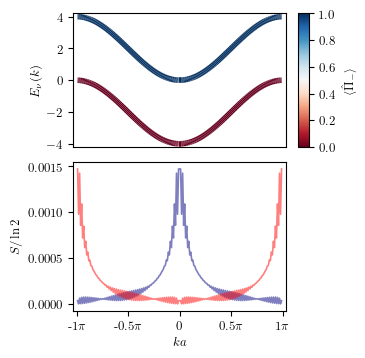

In [76]:
cmap = "RdBu"
cmap_obj = plt.get_cmap(cmap)
c_norm = (0.0, 1.0)
norm = plt.Normalize(*c_norm)

fig = plt.figure(
    figsize=(bwidth, 1.4 * bheight),
    constrained_layout=True
)

gs = fig.add_gridspec(nrows=2,ncols=2,height_ratios=[0.9, 1.0],
    width_ratios=[1.0, 0.055],hspace=0,wspace=0.02)

# Both plot axes use the same left column, so their x-axes align.
ax_top = fig.add_subplot(gs[0, 0])
ax_bottom = fig.add_subplot(gs[1, 0], sharex=ax_top)

# Colorbar axis belongs only to the upper plot.
cax = fig.add_subplot(gs[0, 1])

# Entropy panel
ax_bottom.plot(k_single_band_full,Svn_p_full / np.log(2),color="navy",
    linewidth=1.2, alpha=0.5)

ax_bottom.plot(k_single_band_full,Svn_m_full / np.log(2),color="red",
    linewidth=1.2,alpha=0.5)

# Colored bands
plus_line = plot_colored_line(ax_top,k_single_band_full, over_energies_p_full,
            over_colors_p_full,linewidth=4)
plus_line.set_zorder(20)

minus_line = plot_colored_line(ax_top,k_single_band_full,over_energies_m_full,
    over_colors_m_full,linewidth=4)
minus_line.set_zorder(20)

# First resonant-pair arrow
x1_, x2_ = resonant_pairs[0]
y_ = 1.0


# Colorbar only for the upper panel
sm = plt.cm.ScalarMappable(cmap=cmap_obj, norm=norm)
sm.set_array(
    np.concatenate(
        (over_colors_p_full, over_colors_m_full)
    )
)

cbar = fig.colorbar(sm, cax=cax)
cbar.set_label(r"$\langle \hat{\Pi}_- \rangle$",fontsize=base_font)

# Axis labels
ax_top.set_ylabel(r"$E_{\nu}(k)$",fontsize=base_font)
ax_bottom.set_ylabel(r"$S/\ln{2}$",fontsize=base_font)
ax_bottom.set_xlabel(r"$ka$",fontsize=base_font)

# Shared x-axis limits and ticks
ax_top.set_xlim(-np.pi - 0.1, np.pi + 0.1)
ax_top.set_xticks([-np.pi, -np.pi / 2, 0, np.pi / 2, np.pi])

ax_top.xaxis.set_major_formatter(
matplotlib.ticker.FuncFormatter(
        lambda value, position:
        r"{:.0g}$\pi$".format(value / np.pi)
        if value != 0 else "0"
    )
)

# Hide upper x tick labels; the bottom axis displays the shared labels.
ax_top.tick_params(axis="x",which="both",labelbottom=False,  bottom=False,top=False)

# Top-panel y range
ax_top.set_ylim(-2.2 - t_, 2.2 + t_)

# Panel labels
#ax_top.annotate(r"(a)",xy=(-0.95 * np.pi, 1.72),fontsize=base_font, fontweight="bold")

#ax_bottom.annotate(r"(b)",xy=(-0.95 * np.pi, 0.93), fontsize=base_font,fontweight="bold")

plt.savefig(fig_route + "band_struct_app_{:.4f}.pdf".format(t_), bbox_inches="tight")